# Quantum Dynamics Project

This project numerically explores the dynamics of a one-dimensional quantum particle described by a wavefunction $\Psi(x,t)$ that obeys the time-dependent Schrödinger equation. Analytical solutions are available only for a few simple potentials (infinite square well, harmonic oscillator). For more general potentials, numerical integration is required.

**Objectives**
1. Compute stationary states by diagonalizing the discretized Hamiltonian and validate the method against systems with known analytical solutions.
2. Integrate the time-dependent equation using two schemes (explicit Euler and fourth-order Runge–Kutta), compare their reliability, and validate the selected method.
3. Apply the numerical solver to systems without simple analytical solutions: a wave packet scattering from a potential barrier, and the dynamics of a Bose–Einstein condensate in a double-well potential (Gross–Pitaevskii equation).

**Outline**
1. Stationary states (infinite square well, harmonic potential)
2. Time evolution (Euler, fourth-order Runge–Kutta, Gaussian wave packets)
3. More complex systems (potential barrier, Josephson dynamics with and without interactions)

**Units and conventions.** We use units in which $\hbar = 1$ and $\hbar^2/2m = 1$. The Hamiltonian is therefore
$$\hat H = -\frac{\partial^2}{\partial x^2} + V(x),$$
and the Schrödinger equation becomes $i\,\partial_t\Psi = \hat H\Psi$. In these units, the kinetic energy of a plane wave $e^{ikx}$ is $k^2$ and its group velocity is $2k$. All quantities (lengths, times, and energies) are dimensionless.

**Libraries.** NumPy (array operations), SciPy (`eigh_tridiagonal` for diagonalization), and Matplotlib (plots and animations).

## 1. Stationary States

A stationary state is a solution of the time-independent Schrödinger equation
$$\hat H\,\varphi_p(x) = E_p\,\varphi_p(x).$$
Its probability density $|\Psi|^2$ does not change with time.

**Discretization.** We replace the real line with a finite interval $[-L/2, L/2]$ divided into $n$ interior grid points $x_i$, separated by $\delta x = L/(n+1)$. The second derivative is approximated to second order by
$$\frac{\partial^2\psi}{\partial x^2}\bigg|_{x_i} \approx \frac{\psi_{i+1} - 2\psi_i + \psi_{i-1}}{\delta x^2}.$$
The Hamiltonian is then an $n\times n$ symmetric tridiagonal matrix, with diagonal entries $2/\delta x^2 + V_i$ and off-diagonal entries $-1/\delta x^2$. The problem reduces to an eigenvalue/eigenvector calculation, performed with `eigh_tridiagonal`, which is designed for this type of matrix.

**Boundary conditions.** By retaining only the interior grid points, we impose $\psi(\pm L/2) = 0$: this is equivalent to adding an infinite square well of width $L$ to the potential $V(x)$. The calculation is therefore reliable only if the wavefunction is effectively zero well before reaching the boundaries.

**Validity conditions.** The grid spacing $\delta x$ must be small compared with the length scale over which $\psi$ varies (so $n$ must be large), and the interval $L$ must be large compared with the region occupied by the particle.

In [1]:
# Libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh_tridiagonal   
import matplotlib.animation as animation

# Constants
hbarre=1.054*10**-34

In [2]:
# Stationary-problem solver functions

def schrodinger_stationnaire(L,n,V):
    '''
    discretizes the interval from -L/2 to +L/2 using n grid points spaced by dx and solves the stationary Schrödinger equation 
    for a given V(x), returning the associated eigenvectors (vecteurs_p) and eigenvalues (valeurs_p), as well as the values 
    grid positions and potential values (xi and Vi), grid spacing dx, and Hamiltonian H.
    '''
    dx = L / (n + 1)
    xi = np.linspace(-L/2 + dx, L/2 - dx, n)   # interior grid points only
    Vi = V(xi)
    d = 2/dx**2 + Vi
    e = -1/dx**2 * np.ones(n - 1)
    H = np.diag(d) + np.diag(e, 1) + np.diag(e, -1)
    valeurs_p, vecteurs_p = eigh_tridiagonal(d, e)
    return xi, dx, Vi, valeurs_p, vecteurs_p,H

def normalize(m, dx):
    m = np.array(m, dtype=complex, copy=True)
    norm = np.sqrt(np.sum(np.abs(m)**2) * dx)
    return m / norm

def normalize_psi(psi, dx):             # Normalize a wavefunction vector psi 
    norm = np.sqrt(np.sum(np.abs(psi)**2) * dx)
    return psi / norm

- `schrodinger_stationnaire(L, n, V)` builds the grid and discretized Hamiltonian, then returns the positions `xi`, grid spacing `dx`, potential `Vi`, eigenenergies (in ascending order), eigenvectors as columns, and matrix `H`.
- `normalize` and `normalize_psi` enforce $\int|\psi|^2\,dx = 1$ while accounting for the grid spacing $\delta x$: NumPy eigenvectors are normalized to a sum of squares equal to 1, not to an integral equal to 1.

### 1.1 Infinite Square Well

For the infinite square well ($V = 0$ for $|x| < L/2$), the analytical solution is known:
$$\varphi_p(x) = \sqrt{\frac{2}{L}}\,\sin\!\left(\frac{(p+1)\pi\,(x + L/2)}{L}\right), \qquad E_p = \left(\frac{(p+1)\pi}{L}\right)^2.$$
This case provides a benchmark: if the code reproduces this spectrum and these wavefunctions, it can be trusted for potentials without analytical solutions. We use $L = 5$ and $n = 100$.

In [3]:
# Analytical eigenvalues and eigenvectors for the infinite square well
def Ep_théo_puits(p,L):
    return ((np.pi*(p+1))/L)**2

def phi_theo_puits(x, p, L):
    return np.sqrt(2 / L) * np.sin((p + 1) * np.pi * (x + L/2) / L)

# Infinite square-well parameters
L_puits=5
n_puits=100
def V_puits(x):          #The potential is zero inside the well et infini à l'extérieur
    return x*0

# Numerical values computed with the stationary Schrödinger solver
xi_puits, dx_puits, Vi_puits, vap_puits, vep_puits,H_puits= schrodinger_stationnaire(L_puits,n_puits,V_puits)


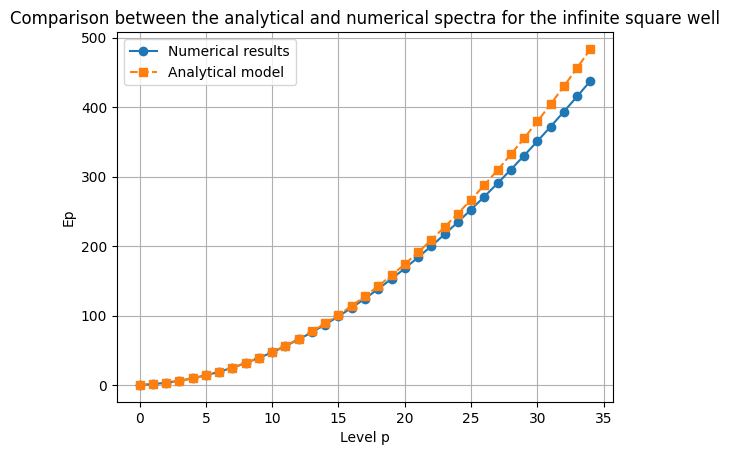

In [4]:
# Comparison of analytical and numerical spectra for the infinite square well
p=np.arange(0,35,1)
plt.plot(p,vap_puits[:len(p)],"o-",label="Numerical results")
plt.plot(p,Ep_théo_puits(p,L_puits),"s--",label="Analytical model")
plt.grid()
plt.xlabel("Level p")
plt.ylabel("Ep")
plt.legend()
plt.title("Comparison between the analytical and numerical spectra for the infinite square well")
plt.savefig('puits_infini_spectre.png')

/Library/Frameworks/Python.framework/Versions/3.8/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


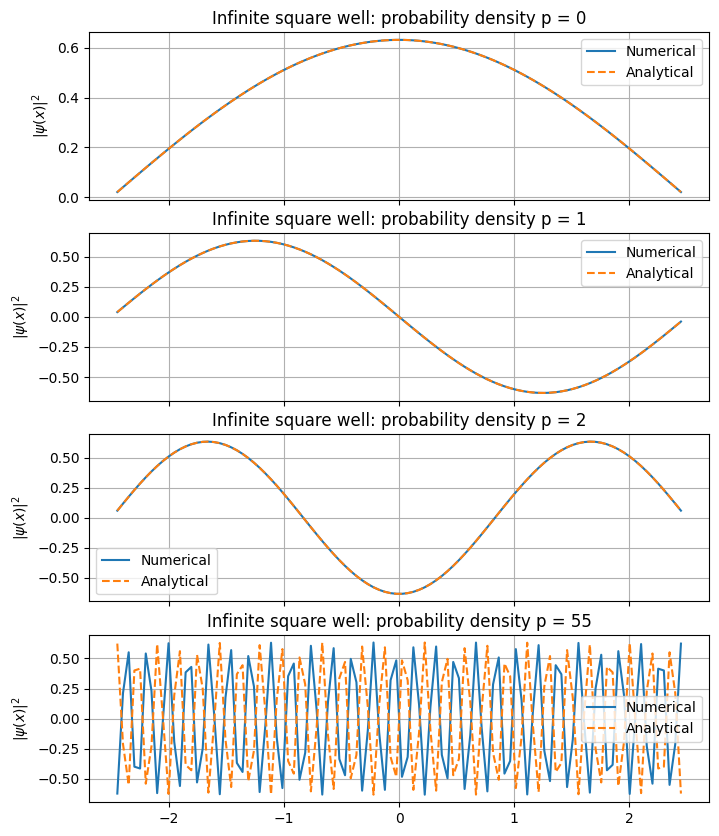

In [5]:
# Comparison of analytical and numerical probability densities 

fig, axes = plt.subplots(4, 1, figsize=(8, 10), sharex=True)

for i in p[:3]:
    axes[i].plot(xi_puits,normalize(vep_puits[:,i],dx_puits), label='Numerical')
    axes[i].plot(xi_puits,normalize(phi_theo_puits(xi_puits,i,L_puits),dx_puits) , '--', label='Analytical')
    axes[i].set_ylabel(r'$|\psi(x)|^2$')
    axes[i].set_title(f'Infinite square well: probability density p = {i}')
    axes[i].grid()
    axes[i].legend()
axes[3].plot(xi_puits,normalize(vep_puits[:,55],dx_puits),label='Numerical')
axes[3].plot(xi_puits,normalize(phi_theo_puits(xi_puits,55,L_puits),dx_puits),'--',label='Analytical')
axes[3].set_ylabel(r'$|\psi(x)|^2$')
axes[3].set_title(f'Infinite square well: probability density p = {55}')
axes[3].grid()
axes[3].legend()
plt.savefig('puits_infini_densite.png')

**Analysis.** For the lowest energy levels, the numerical energies and wavefunctions agree with the analytical results. The discrepancy increases with $p$: the numerical energy is always below the analytical energy, and the difference becomes visible around $p \approx 20$.

This is a discretization effect. The eigenvalues of the tridiagonal matrix are exactly
$$E_p^{\rm num} = \frac{4}{\delta x^2}\sin^2\!\left(\frac{(p+1)\pi}{2(n+1)}\right) < \left(\frac{(p+1)\pi}{L}\right)^2.$$
The $p$-th level has $p+1$ half-wavelengths in the box, corresponding to approximately $2(n+1)/(p+1)$ grid points per wavelength. For $p = 55$ and $n = 100$, there are only 3 or 4 points: this is insufficient to represent the second derivative accurately.

**Conclusion.** With $n = 100$, the code is reliable for the lowest levels (the ones used in the following sections). Higher levels require a larger value of $n$, at the cost of a larger matrix.

### 1.2 Harmonic Potential

The second validation case is the harmonic potential $V(x) = x^2$. In our units ($\hbar^2/2m = 1$), the equation $-\varphi'' + x^2\varphi = E\varphi$ has solutions expressed in terms of Hermite functions: a Gaussian multiplied by a Hermite polynomial. Its energy spectrum is equally spaced:
$$E_p = 2p + 1, \qquad p = 0, 1, 2, \dots$$
Unlike the infinite square well, the particle is confined by the potential itself rather than by the walls. We must therefore choose $L$ large enough that the boundaries have no effect. Here we use $L = 20$ and $n = 100$.

In [6]:
# Analytical eigenvalues and eigenvectors for the harmonic potential 
def Ep_théo_harmonique(p):
    return (2*p+1)

# Harmonic-potential parameters
L_harmo=20
n_harmo=100
def V_harmo(x):
    return x**2

# Numerical values computed with the stationary Schrödinger solver
xi_harmo, dx_harmo, Vi_harmo, vap_harmo, vep_harmo,H_harmo= schrodinger_stationnaire(L_harmo,n_harmo,V_harmo)


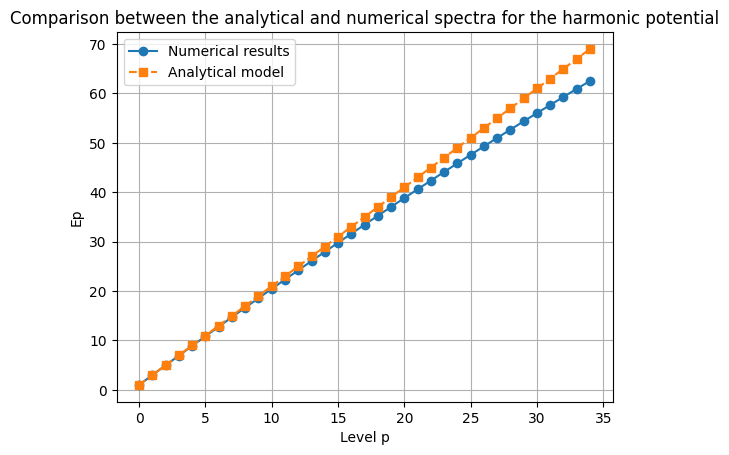

In [7]:
# Comparison of analytical and numerical spectra for the harmonic potential
p=np.arange(0,35,1)
plt.plot(p,vap_harmo[:len(p)],"o-",label="Numerical results")
plt.plot(p,Ep_théo_harmonique(p),"s--",label="Analytical model")
plt.grid()
plt.xlabel("Level p")
plt.ylabel("Ep")
plt.legend()
plt.title("Comparison between the analytical and numerical spectra for the harmonic potential")
plt.savefig('harmonique_spectre.png')

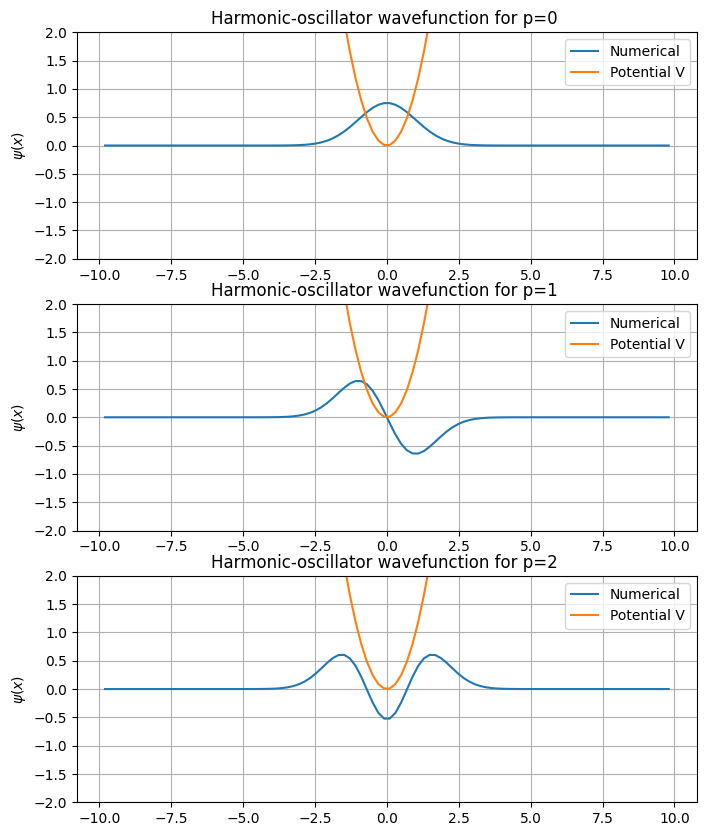

In [8]:
# Wavefunctions for p=0, 1, 2

fig, axes = plt.subplots(3, 1, figsize=(8, 10))
axes[0].plot(xi_harmo,normalize(vep_harmo[:,0],dx_harmo),"-", label='Numerical')
axes[0].plot(xi_harmo,V_harmo(xi_harmo),"-", label='Potential V')
axes[0].set_ylabel(r'$\psi(x)$')
axes[0].set_ylim(bottom=-2, top=2)
axes[0].set_title("Harmonic-oscillator wavefunction for p=0 ")
axes[0].grid()
axes[0].legend()
axes[1].plot(xi_harmo,normalize(vep_harmo[:,1],dx_harmo),"-", label='Numerical')
axes[1].plot(xi_harmo,V_harmo(xi_harmo),"-", label='Potential V')
axes[1].set_ylim(bottom=-2, top=2)
axes[1].set_ylabel(r'$\psi(x)$')
axes[1].set_title("Harmonic-oscillator wavefunction for p=1 ")
axes[1].grid()
axes[1].legend()
axes[2].plot(xi_harmo,normalize(vep_harmo[:,2],dx_harmo),"-", label='Numerical')
axes[2].plot(xi_harmo,V_harmo(xi_harmo),"-", label='Potential V')
axes[2].set_ylabel(r'$\psi(x)$')
axes[2].set_title("Harmonic-oscillator wavefunction for p=2 ")
axes[2].set_ylim(bottom=-2, top=2)
axes[2].grid()
axes[2].legend()
plt.savefig('harmonique_fonctions_ondes.png')

**Analysis.** The numerical spectrum is a straight line with slope 2: the energy levels are equally spaced, as expected for a harmonic oscillator. A discrepancy between the numerical and analytical curves appears from level $p=12$ onward, due to discretization errors. This discrepancy can be reduced by increasing the value of $n$. The wavefunctions have the characteristic shapes of the oscillator: a Gaussian for $p = 0$, an odd function with one node for $p = 1$, and an even function with two nodes for $p = 2$. They are localized within a few units of the origin, far from the boundaries at $\pm 10$: with $L = 20$, the infinite-well boundaries have no effect.

**Conclusion.** The code reproduces the spectrum and the shape of the harmonic-oscillator states. Together with the infinite-square-well test, this validates the diagonalization step.

**Summary of Part 1.** Diagonalization of the discretized Hamiltonian reproduces the analytical results for the infinite square well and the harmonic oscillator, provided that $\delta x$ is small enough (i.e. $n$ is large enough) for the energy level under study, and that $L$ is large enough for the boundaries to have no effect. The resulting eigenstates provide initial states and reference solutions for the time evolution.

## 2. Time Evolution

We now seek the time evolution of an arbitrary initial wavefunction $\Psi(x,0)$. We keep the spatial discretization from Part 1 and also discretize time: $t_k = k\,\delta t$, with $\delta t = T/m$, where $m$ is the number of time steps. The equation $i\,\partial_t\Psi = \hat H\Psi$ becomes a system of ordinary differential equations:
$$\frac{d\boldsymbol\psi}{dt} = -i\,H\,\boldsymbol\psi,$$
which we integrate step by step. The choice of numerical scheme is essential: quantum evolution conserves the norm $\int|\Psi|^2dx = 1$, and a scheme that fails to preserve it can produce incorrect results, even if it appears satisfactory over a few time steps.

The simplest test of a numerical scheme is to apply it to a stationary state: its probability density should remain strictly constant.

In [9]:
# Utility functions for plotting and animating the results

def tracer_densité(t,xi,psi,dt,title:str):
    ''' 
    plots the probability density as a function of x at several times t=0,T/4,T/2,3T/4,T
    '''
    t1=1*len(t)//4
    t2=2*len(t)//4
    t3=3*len(t)//4
    t4=(4*len(t)//4)-1
    plt.plot(xi,np.abs(psi[0])**2,label="t=0")
    plt.plot(xi,np.abs(psi[t1])**2,label=f"t={t1*dt:.2f}")
    plt.plot(xi,np.abs(psi[t2])**2,label=f"t={t2*dt:.2f}")
    plt.plot(xi,np.abs(psi[t3])**2,label=f"t={t3*dt:.2f}")
    plt.plot(xi,np.abs(psi[t4])**2,label=f"t={t4*dt:.2f}")
    plt.legend()
    plt.grid()
    plt.xlabel("x")
    plt.ylabel(r'$ \vert \psi(x) \vert^2$')
    plt.title(title)

# Animation
# Animation libraries
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

def animation(xi,t,psi,step,title:str):
    ''' 
    Creates an animation of the time evolution de the probability density as a function of x over time
    the structure of this code is adapted d'un code trouvé en ligne
    '''
    fig, ax = plt.subplots(figsize=(10,5))

    line, = ax.plot([], [], lw=2, label=r"$|\psi(x,t)|^2$")
    ax.set_xlim(xi[0], xi[-1])
    ax.set_ylim(0, 1.1*np.max(np.abs(psi)**2))
    ax.set_xlabel("x")
    ax.set_ylabel(r'$ \vert \psi(x) \vert^2$')
    ax.set_title(title)
    ax.grid()
    ax.legend()
    
    time_text = ax.text(0.02, 0.95, "", transform=ax.transAxes) 

    def init():
        line.set_data([], [])
        time_text.set_text("")
        return line, time_text

    def update(frame):
        y = np.abs(psi[frame])**2
        line.set_data(xi, y)
        time_text.set_text(f"t = {t[frame]:.4f}")
        return line, time_text

    ani = FuncAnimation(
        fig,
        update,
        frames=range(0, len(t), step),
        init_func=init,
        blit=True,
        interval=30
    )
    plt.close(fig)
    return HTML(ani.to_jshtml())

### 2.1 Explicit Euler Method

The explicit Euler scheme, first-order in $\delta t$, replaces the time derivative with a finite difference:
$$\boldsymbol\psi_{k+1} = \boldsymbol\psi_k - i\,\delta t\,H\boldsymbol\psi_k.$$
It is simple, but, as we will see, poorly suited to the Schrödinger equation. For an eigenstate with energy $E$, each step multiplies the wavefunction by $1 - iE\,\delta t$, whose modulus is $\sqrt{1 + E^2\delta t^2} > 1$: the scheme is unstable for any nonzero $\delta t$. In the code, the wavefunction is renormalized at every step, which artificially keeps its norm equal to 1 but does not correct the distortion of the probability density.

In [10]:
def schrodinger_dynamique_euler(L, n, T, m, V, psi0):
    """
    Solves i dpsi/dt = H psi using the explicit Euler algorithm :
        psi_t{k+1} = psi_tk - i dt H psi_tk
    over a total duration of T, with m time steps of size dt
    Returns xi, t, dx, dt, and psi(x,t)
    """
    xi, dx, Vi, valeurs_p, vecteurs_p,H =schrodinger_stationnaire(L,n,V)
    dt = T / m
    t = np.linspace(0, T, m + 1)

    psi = np.zeros((m + 1, n), dtype=complex)
    psi[0] = normalize_psi(psi0,dx)
    for k in range(m):
        psi[k + 1] = normalize_psi(psi[k] - 1j * dt * (H @ psi[k]),dx)

    return xi, t, psi,dt,dx

In [11]:
#Parameters for the infinite square well
T_puits_e=1
m_puits_e=10000
psi0=vep_puits[:,0] # Use the ground-state eigenvector of the infinite square well as the initial state

In [12]:
#Numerical results obtained with schrodinger_dynamique_euler
xi_e_puits,t_e_puits,psi_e_puits,dt_e_puits,dx=schrodinger_dynamique_euler(L_puits, n_puits, T_puits_e, m_puits_e, V_puits, psi0)

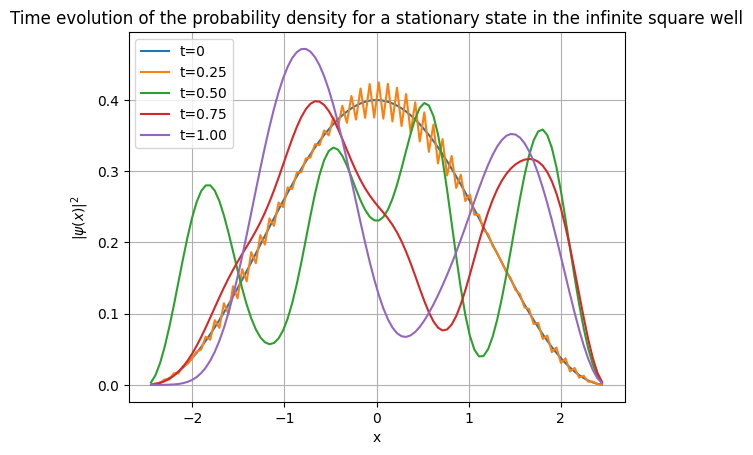

In [13]:
tracer_densité(t_e_puits,xi_e_puits,psi_e_puits,dt_e_puits,"Time evolution of the probability density for a stationary state in the infinite square well")

**Analysis.** A stationary state of the infinite square well does not remain stationary: rapid oscillations appear in the density as early as $t = 0.25$, and its shape is completely distorted by $t = 1$. The result is incorrect even after renormalization. The error could be reduced by greatly increasing the number of time steps $m$, but the computational cost would become excessive.

**Conclusion.** Explicit Euler is not suitable for the Schrödinger equation: a more appropriate scheme is required.

The stationary state does not remain stationary and evolves over time. The Euler algorithm is therefore not accurate enough. Increasing $m$ by several orders of magnitude gives a result closer to the expected behavior, but requires a very large computational effort.

### 2.2 Runge–Kutta Method

The fourth-order Runge–Kutta method (RK4) evaluates the derivative at four intermediate points during each time step. With $f(\boldsymbol\psi) = -iH\boldsymbol\psi$:
$$\boldsymbol\psi_{k+1} = \boldsymbol\psi_k + \frac{\delta t}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right),$$
$$k_1 = f(\boldsymbol\psi_k),\quad k_2 = f\!\left(\boldsymbol\psi_k + \tfrac{\delta t}{2}k_1\right),\quad k_3 = f\!\left(\boldsymbol\psi_k + \tfrac{\delta t}{2}k_2\right),\quad k_4 = f(\boldsymbol\psi_k + \delta t\,k_3).$$
RK4 does not conserve the norm exactly, but the drift remains small as long as $\delta t$ is sufficiently small. We therefore do not renormalize the wavefunction at every step, so that the conservation properties can be assessed honestly.

In [14]:
def schrodinger_dynamique_rk4(L, n, T, m, V, psi0):
    """
    Solves i dpsi/dt = H psi using RK4.
    We write:
        dpsi/dt = f(psi) = -i H psi
    over a total duration T with m time steps of size dt
    Returns xi, t, dx, dt, and psi(x,t)
    """
    xi, dx, Vi, valeurs_p, vecteurs_p,H =schrodinger_stationnaire(L,n,V)

    dt = T / m
    t = np.linspace(0, T, m + 1)

    psi = np.zeros((m + 1, n),dtype=complex)
    psi[0] = normalize_psi(psi0,dx)

    def f(psi_vec):
        return -1j * (H @ psi_vec)

    for k in range(m):
        k1 = f(psi[k])
        k2 = f(psi[k] + 0.5 * dt * k1)
        k3 = f(psi[k] + 0.5 * dt * k2)
        k4 = f(psi[k] + dt * k3)

        psi[k + 1] = psi[k] + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

    return xi, t, psi,dt,dx,H

In [15]:
# Utility functions

def valeur_moyenne_energie(psi, H, dx):
    """
    Computes the mean energy :
    <E> = <psi|H|psi>
    """
    return np.real(np.vdot(psi, H @ psi) * dx)


def valeur_moyenne_impulsion(psi, dx):
    """
    Computes the mean momentum :
    <p> = <psi|p|psi>, with p = -i d/dx
    """
    dpsi_dx = np.zeros_like(psi, dtype=complex)

    # Centered finite difference at interior points
    dpsi_dx[1:-1] = (psi[2:] - psi[:-2]) / (2 * dx)

    # Forward/backward differences at the boundaries
    dpsi_dx[0] = (psi[1] - psi[0]) / dx
    dpsi_dx[-1] = (psi[-1] - psi[-2]) / dx

    ppsi = -1j * dpsi_dx

    return np.real(np.vdot(psi, ppsi) * dx)


def valeur_moyenne_impulsion_carre(psi, dx):
    """
    Computes the mean momentum au carré <p^2>.

    On utilise l'opérateur :
        p^2 = - d²/dx²
    """
    d2psi_dx2 = np.zeros_like(psi, dtype=complex)

    # Centered finite difference at interior points
    d2psi_dx2[1:-1] = (psi[2:] - 2*psi[1:-1] + psi[:-2]) / dx**2

    # bords : on laisse 0, ce qui est cohérent si psi s'annule aux extrémités
    p2psi = -d2psi_dx2

    num = np.vdot(psi, p2psi) * dx
    den = np.vdot(psi, psi) * dx

    return np.real(num / den)

def valeur_moyenne_position(psi, x, dx):
    """
    Calcule la valeur moyenne de la position :
    <x> = <psi|x|psi> / <psi|psi>
        Valeur moyenne de la position.
    """
    num = np.vdot(psi, x * psi) * dx
    den = np.vdot(psi, psi) * dx
    return np.real(num / den)


def valeur_moyenne_position_carre(psi, x, dx):
    """
    Calcule la valeur moyenne de la position :
    <x^2> = <psi|x^2|psi> / <psi|psi>
        Valeur moyenne de la position.
    """
    num = np.vdot(psi, (x**2) * psi) * dx
    den = np.vdot(psi, psi) * dx
    return np.real(num / den)


def verifie_heisenberg(psi, x, dx):
    """
    Vérifie l'inégalité de Heisenberg :
        delta_x * delta_p >= 1/2
    """
    x_moy = valeur_moyenne_position(psi, x, dx)
    x2_moy = valeur_moyenne_position_carre(psi, x, dx)

    p_moy = valeur_moyenne_impulsion(psi, dx)
    p2_moy = valeur_moyenne_impulsion_carre(psi, dx)

    delta_x2 = x2_moy - x_moy**2
    delta_p2 = p2_moy - p_moy**2

    delta_x = np.sqrt(delta_x2)
    delta_p = np.sqrt(delta_p2)

    heisenberg = delta_x * delta_p
    return heisenberg

def integrale_densite_entre_bornes(psi, x, a, b, dx):
    ''' 
    fais l'intégrale de the probability density entre x=a et x=b 
    '''
    valeurs = np.logical_and(x >= a, x <= b)    #sélectionne les valeurs xi tels que a<=xi<=b 
    return np.sum(np.abs(psi[valeurs])**2) * dx  #intégrale par somme de rectangles

def tracer_eih(t,xi,psi,H,dx,title:str):
    energie = np.array([valeur_moyenne_energie(psi[i],H,dx) for i in range(len(psi))])
    impulsion =  np.array([valeur_moyenne_impulsion(psi[i],dx) for i in range(len(psi))])
    heisenberg =np.array([verifie_heisenberg(psi[i],xi,dx) for i in range(len(psi))])
    borne_heisenberg=np.array([1/2 for i in range(len(psi))])
    fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)


    axes[0].plot(t,energie)
    axes[0].set_ylabel(r"$ \langle E \rangle $")
    axes[0].set_title(f"Time evolution of the mean energy for the {title}")
    axes[0].grid()
    axes[0].legend()

    axes[1].plot(t,impulsion)
    axes[1].set_ylabel(r"$ \langle P \rangle $")
    axes[1].set_title(f"Time evolution of the mean momentum for the {title}")
    axes[1].grid()
    axes[1].legend()

    axes[2].plot(t,heisenberg)
    axes[2].plot(t,borne_heisenberg,'--',label='1/2')
    axes[2].set_ylabel(r"$ \Delta x\, \Delta p $")
    axes[2].set_title(f"Time evolution of the Heisenberg inequality for the {title}")
    axes[2].grid()
    axes[2].legend()

To validate the dynamics, we track several physical quantities over time, calculated using operators in the position representation (finite-difference derivatives):
- the mean energy $\langle E\rangle = \langle\psi|H|\psi\rangle$, which should remain constant because $H$ is time-independent;
- the mean momentum $\langle p\rangle = \langle\psi|(-i\,\partial_x)|\psi\rangle$;
- the uncertainty product $\Delta x\,\Delta p$, which must remain greater than or equal to $1/2$ (Heisenberg uncertainty relation with $\hbar = 1$).

In [16]:
# Test case: infinite square well 

# Infinite square-well parameters
T_puits_r=1
m_puits_r=10000

In [17]:
# Numerical evolution in the infinite square well using schrodinger_dynamique_rk4
xi_r_puits,t_r_puits,psi_r_puits,dt_r_puits,dx_puits,H_puits=schrodinger_dynamique_rk4(L_puits, n_puits, T_puits_r, m_puits_r, V_puits, psi0)

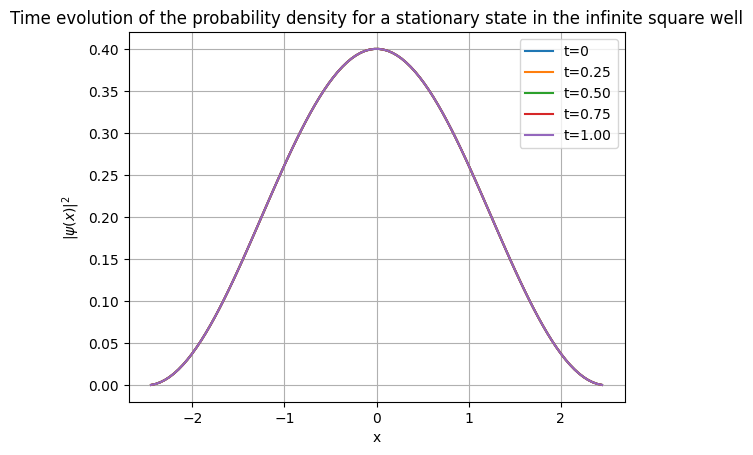

In [18]:
tracer_densité(t_r_puits,xi_r_puits,psi_r_puits,dt_r_puits,"Time evolution of the probability density for a stationary state in the infinite square well")

**Analysis.** With RK4 and the same parameters, the probability density of a stationary state in the infinite square well remains unchanged at all times ($t = 0$ to $t = 1$): the curves overlap.

**Conclusion.** RK4 passes this test and is used in the remainder of the project.

### A. Gaussian Wave Packet in an Infinite Square Well

A Gaussian wave packet is a minimum-uncertainty state: $\Delta x\,\Delta p = 1/2$ at the initial time. It describes a particle approximately localized around $x_0$, with mean momentum $\langle p\rangle = k_0$. Here $a = 1$, $k_0 = 1$, and $x_0 = 0$: the initial width is $\sigma_x = a/2$, the mean energy is $\langle E\rangle = k_0^2 + 1/a^2 = 2$, and the velocity of the packet center is $2k_0 = 2$ in our units.

The Gaussian wave-packet profile is
$$ \psi(x) = \left(\frac{2}{\pi a^2} \right)^{1/4} e^{ik_0 x- \frac{x^2}{a^2}} $$

In [19]:
# Test the Gaussian wave-packet function 
def gaussien(x, a, k0,x0):
    return (2 / (np.pi * a**2))**0.25 * np.exp(1j * k0 * (x-x0) - (x-x0)**2 / a**2)
psi_0_gaussien=gaussien(xi_e_puits,1,1,0) # Use a Gaussian wave packet centered at 0 with nonzero initial velocity as the initial state
xi_r_puits_1g,t_r_puits_1g,psi_r_puits_1g,dt_r_puits_1g,dx_puits_1g,H_puits_1g=schrodinger_dynamique_rk4(L_puits, n_puits, T_puits_r, m_puits_r, V_puits, psi_0_gaussien)

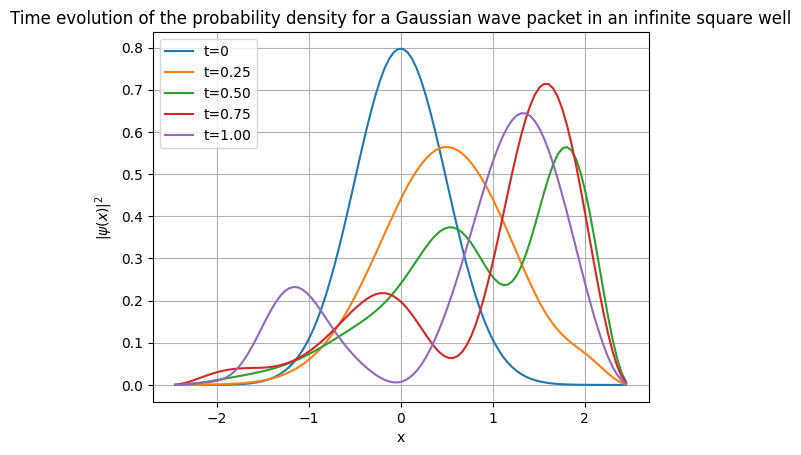

In [20]:
tracer_densité(t_r_puits_1g,xi_r_puits_1g,psi_r_puits_1g,dt_r_puits_1g,"Time evolution of the probability density for a Gaussian wave packet in an infinite square well")    

In [ ]:
animation(xi_r_puits_1g,t_r_puits_1g,psi_r_puits_1g,100,"Time evolution of the probability density for a Gaussian wave packet in an infinite square well")

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


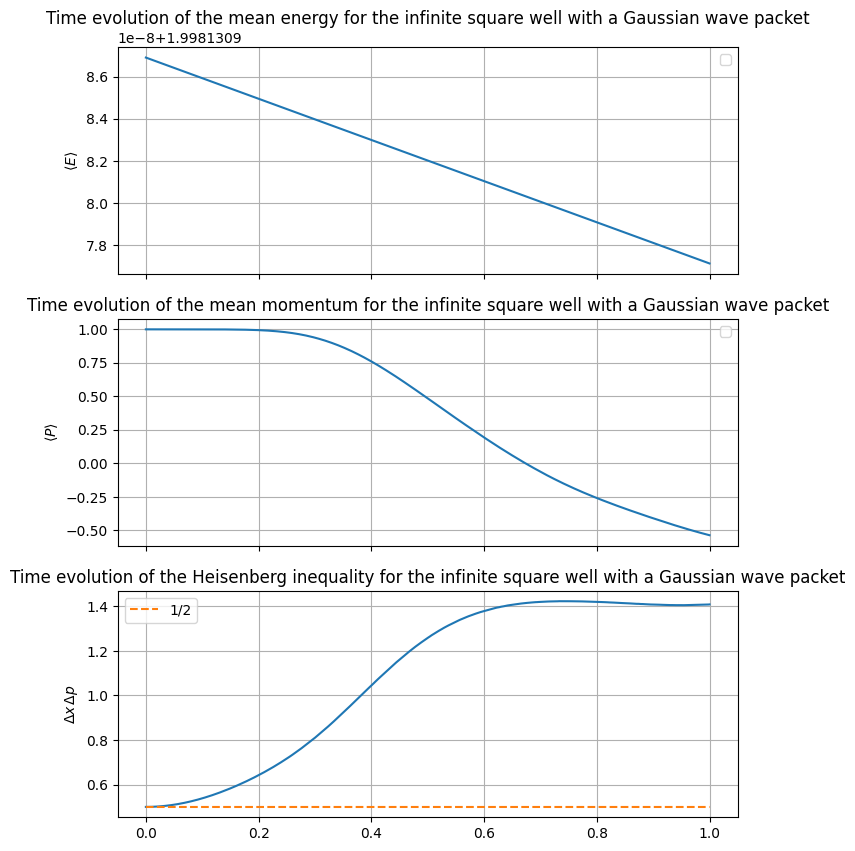

In [22]:
tracer_eih(t_r_puits_1g,xi_r_puits_1g,psi_r_puits_1g,H_puits_1g,dx_puits_1g,"infinite square well with a Gaussian wave packet")

**Analysis.** The packet initially spreads as a free particle would: its maximum decreases from about 0.8 to about 0.56 at $t = 0.25$. It then reaches the wall, is fully reflected, and interferes with its reflected part. The plots of $\langle E\rangle$, $\langle p\rangle$, and $\Delta x\,\Delta p$ show that the energy remains constant, the mean momentum changes sign upon reflection, and the Heisenberg uncertainty relation is respected.

**Animation: Gaussian packet reflection in the infinite square well.** See [`gaussian_packet_infinite_well.gif`](../figures/gaussian_packet_infinite_well.gif)

### B. Two Gaussian Wave Packets Centered at -1 and 1 in an Infinite Square Well

We use two narrow packets ($a = 0.25$), centered at $x_0 = \pm 1$, with zero initial velocity ($k_0 = 0$) and the same phase. A packet that is narrow in position has a large momentum spread and therefore spreads rapidly. By symmetry, we expect $\langle x\rangle = 0$ and $\langle p\rangle = 0$ at all times.

In [23]:
# Test case: two Gaussian wave packets 
psi_0_gaussien=gaussien(xi_e_puits,0.25,0,-1)+gaussien(xi_e_puits,0.25,0,1) # Use two Gaussian wave packets centered at -1 and 1, with zero initial velocity, as the initial state
xi_r_puits_2g,t_r_puits_2g,psi_r_puits_2g,dt_r_puits_2g,dx_puits_2g,H_puits_2g=schrodinger_dynamique_rk4(L_puits, n_puits, T_puits_r, m_puits_r, V_puits, psi_0_gaussien)

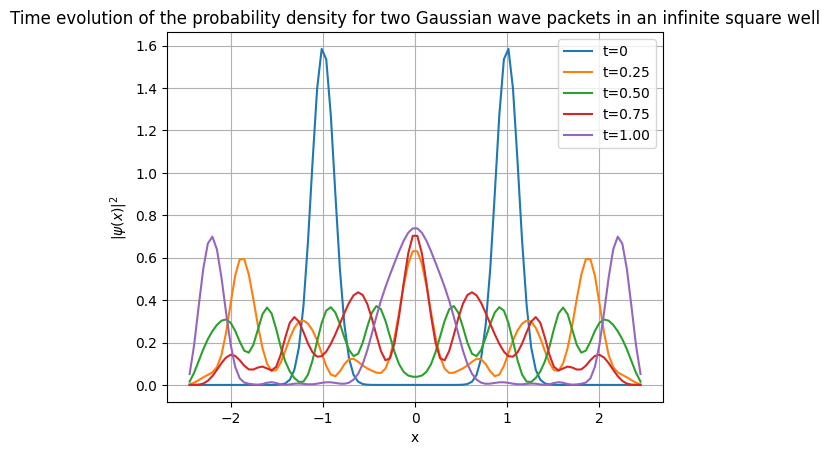

In [24]:
tracer_densité(t_r_puits_2g,xi_r_puits_2g,psi_r_puits_2g,dt_r_puits_2g,"Time evolution of the probability density for two Gaussian wave packets in an infinite square well")

In [ ]:
animation(xi_r_puits_2g,t_r_puits_2g,psi_r_puits_2g,50,"Time evolution of the probability density for two Gaussian wave packets in an infinite square well")

The two wave packets spread and interfere with each other.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


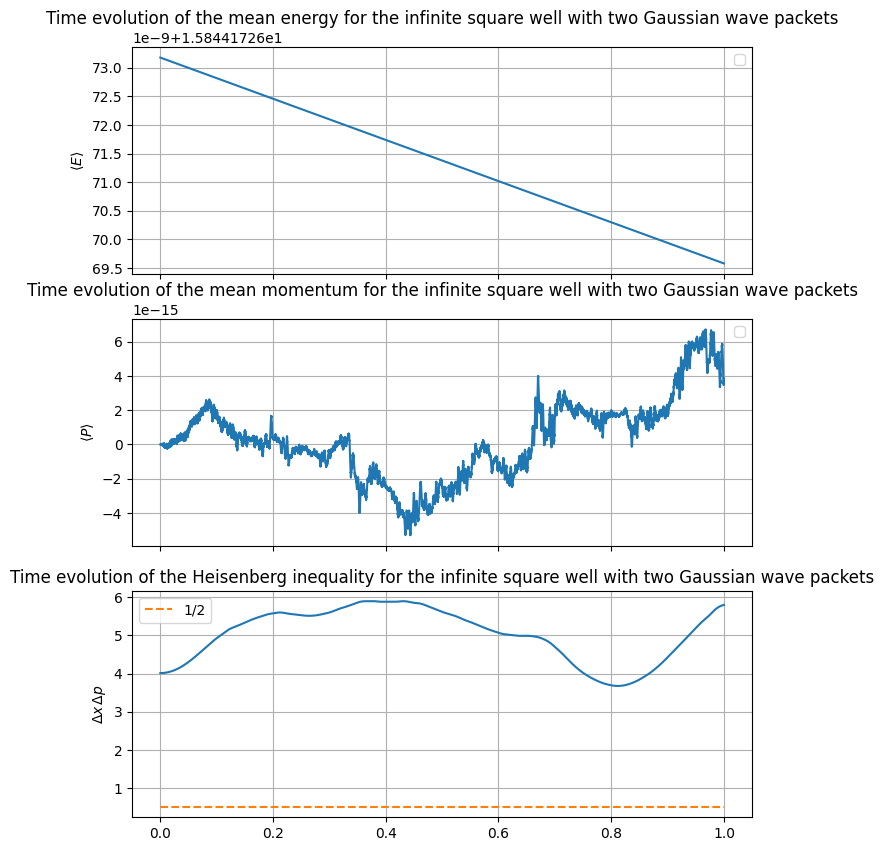

In [26]:
tracer_eih(t_r_puits_2g,xi_r_puits_2g,psi_r_puits_2g,H_puits_2g,dx_puits_2g,"infinite square well with two Gaussian wave packets")

**Analysis.** The two packets spread, meet at the center, and overlap. In the overlap region, the probability density is not the sum of the two individual densities: the amplitudes add before being squared, producing interference fringes. This effect has no classical counterpart and confirms that the code evolves the complex amplitude $\Psi$, rather than only the probability density.

**Animation: interference of two Gaussian wave packets.** See [`two_packet_interference.gif`](../figures/two_packet_interference.gif)

### C. Gaussian Wave Packet in a Harmonic Potential

For the potential $V = x^2$ (with $\hat H = -\partial_x^2 + x^2$), the energy levels are separated by $\hbar\omega = 2$, so the natural angular frequency is $\omega = 2$. A Gaussian packet released away from the center oscillates around $x = 0$ with this period.

In [27]:
#Parameters for the harmonic potential
T_harmo_r=3
m_harmo_r=10000
L_harmo_r=20
n_harmo_r=100
psi_0_gaussien=gaussien(xi_puits,0.25,5,-1) #we use as the initial state un Gaussian wave packet centered at -1 with nonzero initial velocity
xi_r_harmo_1g,t_r_harmo_1g,psi_r_harmo_1g,dt_r_harmo_1g,dx_harmo_1g,H_harmo_1g=schrodinger_dynamique_rk4(L_harmo_r, n_harmo_r, T_harmo_r, m_harmo_r, V_harmo, psi_0_gaussien)

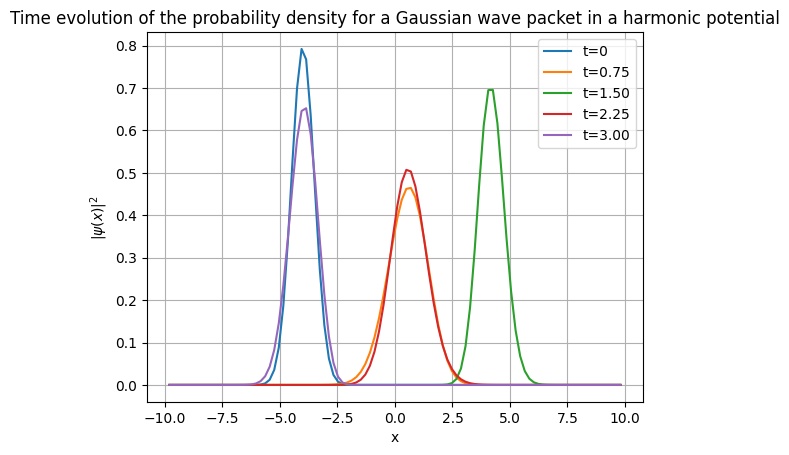

In [28]:
tracer_densité(t_r_harmo_1g,xi_r_harmo_1g,psi_r_harmo_1g,dt_r_harmo_1g,"Time evolution of the probability density for a Gaussian wave packet in a harmonic potential")

In [ ]:
animation(xi_r_harmo_1g,t_r_harmo_1g,psi_r_harmo_1g,100,"Time evolution of the probability density for a Gaussian wave packet in a harmonic potential")

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


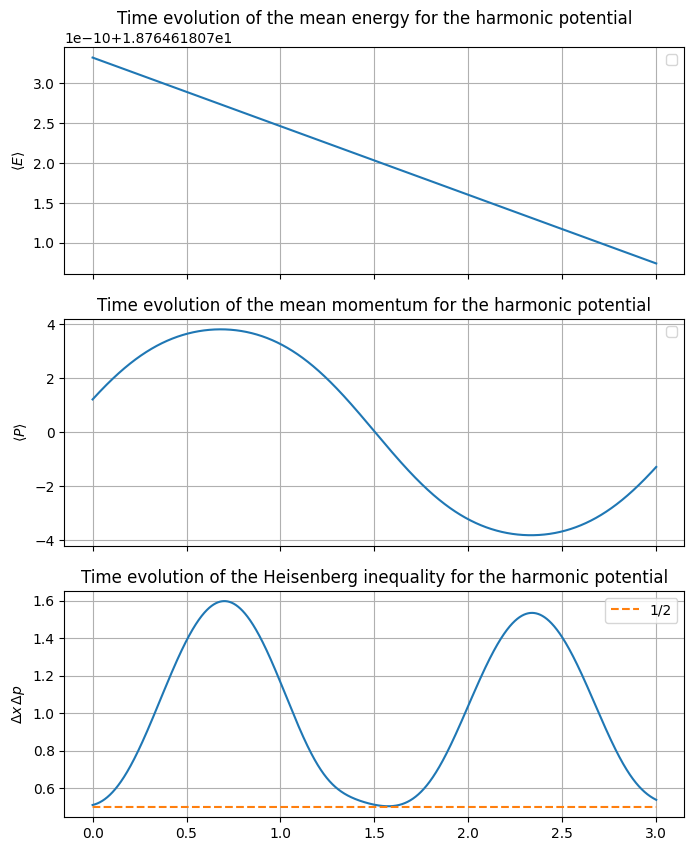

In [30]:
tracer_eih(t_r_harmo_1g,xi_r_harmo_1g,psi_r_harmo_1g,H_harmo_1g,dx_harmo_1g,"harmonic potential")

**Analysis.** The center of the packet oscillates on either side of the origin with the expected period $\pi$: it returns close to its initial position around $t \approx 3$. Its width varies periodically (narrower at the turning points and broader near the center), because the initial state is narrower than the ground state. The mean energy remains constant and $\Delta x\,\Delta p \geq 1/2$ at all times.

**Conclusion of Part 2.** RK4 reproduces the expected behaviors (free spreading, reflection from a wall, interference, and harmonic oscillation). The numerical solver is validated and can now be applied to systems without analytical solutions.

**Animation: Gaussian packet in a harmonic potential.** See [`gaussian_packet_harmonic.gif`](../figures/gaussian_packet_harmonic.gif)

# 3. Applications to More Complex Systems

The validated solver is now applied to two situations without straightforward analytical solutions: the scattering of a wave packet by a potential barrier, followed by the dynamics of ultracold atoms in a double-well potential, where a nonlinear interaction term is added.

## 3.1 Potential Barrier

A narrow Gaussian wave packet ($a = 0.25$, $x_0 = -2$, $k_0 = 10$) is sent toward a barrier of height $V_0 = 100$ and width 2. Its mean energy ($\approx k_0^2 = 100$) is of the same order as the barrier height. Quantum mechanically, part of the wave is reflected and part is transmitted, through tunneling or over-barrier propagation.

To quantify this, we integrate the probability density on each side of the barrier at the final time: $R = \int_{-L/2}^{-a}|\psi|^2dx$ and $T = \int_{a}^{L/2}|\psi|^2dx$.

In [31]:
H=100
a=1
def V_marche(x):
    V=np.zeros(len(x))
    for i in range(len(x)):
        if np.abs(x[i])<=a:
            V[i]=H
        else:
            V[i]=0
    return V
def V_nul(x):
    return x*0
L_marche=20
n_marche=200
T_marche=0.5
m_marche=10000

In [32]:
xi_marche, dx_marche, Vi_marche, vap_marche, vep_marche,H_marche= schrodinger_stationnaire(L_marche,n_marche,V_marche)

In [33]:
psi_0_gaussien=gaussien(xi_marche,0.25,10,-2)

In [34]:
xi_marche,t_marche,psi_marche,dt_marche,dx_marche,H_marche=schrodinger_dynamique_rk4(L_marche, n_marche, T_marche, m_marche, V_marche, psi_0_gaussien)

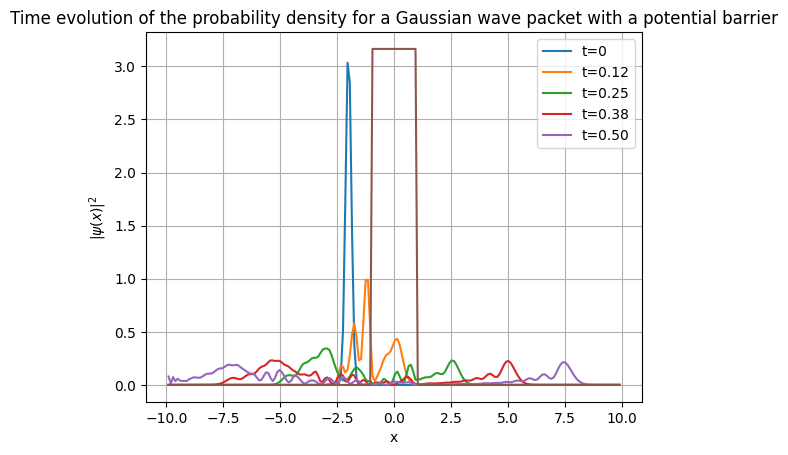

In [35]:
tracer_densité(t_marche,xi_marche,psi_marche,dt_marche,"Time evolution of the probability density for a Gaussian wave packet with a potential barrier")
plt.plot(xi_marche,Vi_marche / np.max(Vi_marche)  * np.max(np.abs(psi_marche)**2))

In [ ]:
# Animation

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Figure
fig, ax = plt.subplots(figsize=(10,5))

line, = ax.plot([], [], lw=2, label=r"$|\psi(x,t)|^2$")

# potential rescaled to be visible on the same plot

pot_line, = ax.plot(xi_marche,Vi_marche / np.max(Vi_marche)  * np.max(np.abs(psi_marche)**2), '--', label="Potential barrier")

ax.set_xlim(xi_marche[0], xi_marche[-1])
ax.set_ylim(0, 1.1*np.max(np.abs(psi_marche)**2))
ax.set_xlabel("x")
ax.set_ylabel("Probability density")
ax.set_title("Time evolution of the probability density for a Gaussian wave packet with a potential barrier")
ax.grid()
ax.legend()

# Time label displayed on the plot
time_text = ax.text(0.02, 0.95, "", transform=ax.transAxes)

def init():
    line.set_data([], [])
    time_text.set_text("")
    return line, time_text

def update(frame):
    y = np.abs(psi_marche[frame])**2
    line.set_data(xi_marche, y)
    time_text.set_text(f"t = {t_marche[frame]:.4f}")
    return line, time_text

# on saute des frames pour éviter une animation trop lourde
step = 50

ani = FuncAnimation(
    fig,
    update,
    frames=range(0, len(t_marche), step),
    init_func=init,
    blit=True,
    interval=30
)

plt.close(fig)
HTML(ani.to_jshtml())

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


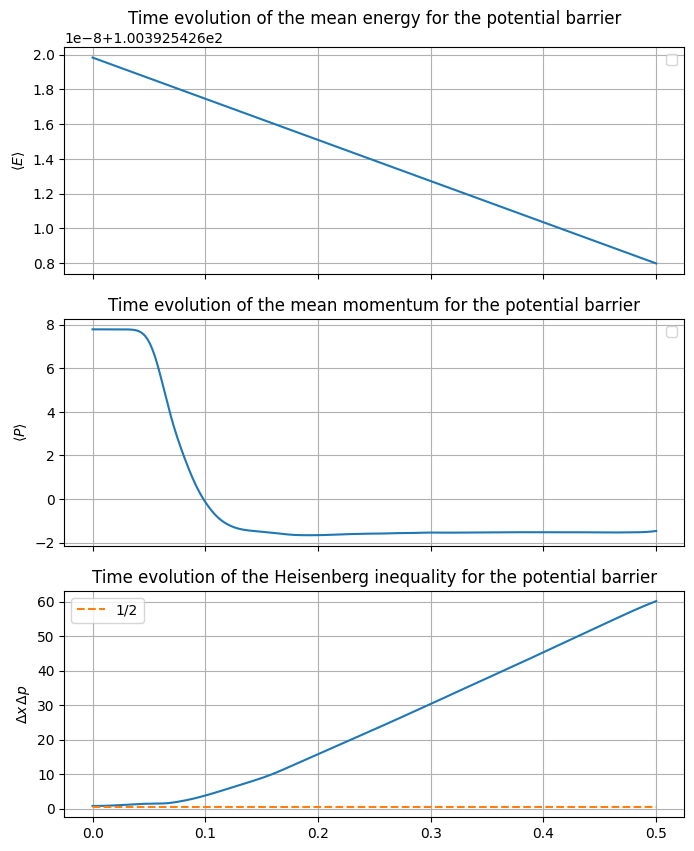

In [37]:
tracer_eih(t_marche,xi_marche,psi_marche,H_marche,dx_marche,"potential barrier")

In [38]:
reflexion_marche=integrale_densite_entre_bornes(psi_marche[-1],xi_marche,-L_marche/2,-a,dx_marche)
transmission_marche=integrale_densite_entre_bornes(psi_marche[-1],xi_marche,a,L_marche/2,dx_marche)
total_marche=reflexion_marche+transmission_marche

In [39]:
print(f"The reflection coefficient is {reflexion_marche:.2f}, and the transmission coefficient is {transmission_marche:.2f} giving a total of {total_marche:.2f}")

The reflection coefficient is 0.66, and the transmission coefficient is 0.31 giving a total of 0.97


**Analysis.** We obtain $R = 0.66$ and $T = 0.31$, so $R + T = 0.97$. The missing 3% corresponds to the probability still located in the barrier region ($|x| < 1$) and to numerical errors. The animation shows the packet splitting into two: one part travels back to the left, while the other passes through the barrier.

**Limitations.** The packet is narrow in position and therefore broad in energy: the reported values are averages over a wide range of $k$. With $n = 200$ (so $\delta x \approx 0.1$), the width $\sigma_x = 0.125$ is only marginally resolved, which explains the small spurious oscillations in the densities. For a more precise study, we would increase $n$ and plot $R$ and $T$ as functions of $k_0$, comparing them with the analytical transmission coefficient for a rectangular barrier.

**Animation: scattering from a potential barrier.** See [`potential_barrier_scattering.gif`](../figures/potential_barrier_scattering.gif)

## 3.2 Josephson Dynamics

**Context.** We study the dynamics of a Bose–Einstein condensate of ultracold atoms trapped in a double-well potential, as in the experiment by Albiez *et al.* (Phys. Rev. Lett. **95**, 010402, 2005). The condensate is described by a macroscopic wavefunction $\Psi(x,t)$. Two effects compete:
- **tunneling** through the central barrier, which tends to equalize the populations of the two wells;
- **repulsive interactions** between atoms, which oppose this transfer.

Interactions are included through the nonlinear term in the **Gross–Pitaevskii equation**:
$$i\,\partial_t\Psi = \left[-\partial_x^2 + V(x) + g\,|\Psi|^2\right]\Psi,$$
where $g$ measures the interaction strength ($g = 0$ recovers the linear Schrödinger equation). We retain the units $\hbar = 1$ and $\hbar^2/2m = 1$ used throughout the project. The potential consists of a harmonic trap plus a central barrier:
$$V(x)=\frac{1}{2}\omega^2 x^2 + V_0\cos^2\left(\pi\frac{x-x_0}{d}\right).$$

**Objective.** The paper predicts two dynamical regimes, depending on the relative importance of tunneling and interactions:
- **Josephson oscillations**, in which atoms move back and forth between the wells;
- **macroscopic quantum self-trapping**, in which atoms remain in the well where they started.

We aim to reproduce both regimes using the RK4 solver for the Gross–Pitaevskii equation. We start from a condensate **at rest**, prepared with an initial population imbalance $z_0$ between the two wells (for example, $z_0 = 0.7$: 85% of the atoms in the left well), and let it evolve in the symmetric double well. The imbalance at time $t$ is $z = N_L - N_R$, where $N_L$ and $N_R$ are the populations in the left and right wells.

**Parameter comparing tunneling and interactions.** The interaction strength is meaningful only relative to tunneling. We compare them using the dimensionless parameter
$$\Lambda = \frac{gI}{2K},$$
where $K = (E_1 - E_0)/2$ is half the tunneling splitting between the two lowest levels of the double well (the higher the barrier, the smaller $K$), and $I = \int\varphi_L^4\,dx$ sets the interaction energy $gI$ in one well ($\varphi_L$ is the mode localized in the left well). When $\Lambda$ is small, tunneling dominates and atoms oscillate between the wells; when $\Lambda$ is large, interactions keep atoms in their initial well. We therefore choose $g$ by fixing the desired value of $\Lambda$.

**Plan.**
1. Choose potential parameters that allow tunneling, then calculate $K$, $I$, and $\Lambda$ using `schrodinger_stationnaire`.
2. Prepare the initial state and integrate the Gross–Pitaevskii equation with `schrodinger_dynamique_josephson_rk4` for three interaction strengths ($\Lambda = 0$, $3$, and $10$), at fixed initial imbalance ($z_0 = 0.7$).
3. Compare the left- and right-well populations in all three cases.

**Interaction condition.** Both $2K$ and the interaction energy $gI$ must remain small compared with the gap $E_2 - E_1$ to the excited states of the well; otherwise, interactions distort the localized states too strongly. This condition is checked in the following code cell.

   **Two-mode approximation.** When the wells are well separated, each one can be described by a single localized mode. The dynamics then depends only on $\Lambda$, and self-trapping occurs when $\Lambda$ exceeds a threshold $\Lambda_c(z_0) = 2\left(1+\sqrt{1-z_0^2}\right)/z_0^2$. For $z_0 = 0.7$, this gives $\Lambda_c \approx 7$.

In [40]:
# Josephson potential

omega = 0.3
V0 = 2
x0 = 0
d = 8

def V_josephson(x):
    return 0.5 * omega**2 * x**2 + V0 * np.cos(np.pi * (x - x0) / d)**2



# RK4 solver for the Gross–Pitaevskii equation
# i dpsi/dt = [H + g|psi|^2] psi
def schrodinger_dynamique_josephson_rk4(L, n, T, m, V, psi0, g):
    """
    Solves the equation:
        i dpsi/dt = [H + g |psi|^2] psi
    using RK4.
    """
    xi, dx, Vi, vap, vep, H = schrodinger_stationnaire(L, n, V)

    dt = T / m
    t = np.linspace(0, T, m + 1)

    psi = np.zeros((m + 1, n), dtype=complex)
    psi[0] = normalize_psi(psi0, dx)

    def f(psi_vec):
        # Linear term + nonlinear Gross–Pitaevskii term
        return -1j * (H @ psi_vec + g * np.abs(psi_vec)**2 * psi_vec)

    for k in range(m):
        k1 = f(psi[k])
        k2 = f(psi[k] + 0.5 * dt * k1)
        k3 = f(psi[k] + 0.5 * dt * k2)
        k4 = f(psi[k] + dt * k3)

        psi[k + 1] = psi[k] + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)


    return xi, t, psi, dt, dx, H, Vi

E0 = 1.1429, E1 = 1.1646, E2 = 1.960
K = 0.01087, I = 0.2771, linear Josephson period pi/K = 289
Validity of the two-mode model: 2K/(E2-E1) = 0.027 (small compared with 1)
RK4 stability: dt = 0.0175, dt*Emax = 1.95 (< 2.8)


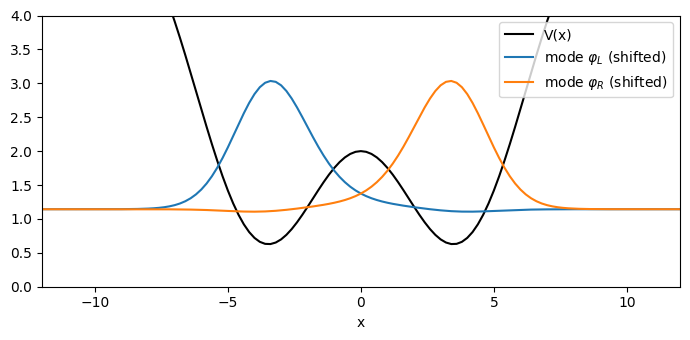

In [41]:
# Initial conditions

L_josephson = 30
n_josephson = 149
T_josephson = 350
m_josephson = 20000

xi_j, dx_j, Vi_j, vap_j, vep_j, H_j = schrodinger_stationnaire(L_josephson, n_josephson, V_josephson)

# Two lowest eigenstates (even and odd), followed by modes localized in each well
phi_0 = normalize(vep_j[:, 0], dx_j).real
phi_1 = normalize(vep_j[:, 1], dx_j).real
phi_L = (phi_0 + phi_1) / np.sqrt(2)
phi_R = (phi_0 - phi_1) / np.sqrt(2)
if np.sum(phi_L[xi_j < 0]**2) < np.sum(phi_L[xi_j > 0]**2):
    phi_L, phi_R = phi_R, phi_L          # phi_L is the mode localized in the left well

# Parameters of the two-mode model
K_j = (vap_j[1] - vap_j[0]) / 2          # demi-séparation tunnel
I_j = np.sum(phi_L**4) * dx_j            # intégrale de phi_L^4

def Lambda_j(g):
    return g * I_j / (2 * K_j)

def g_pour_Lambda(Lam):
    return Lam * 2 * K_j / I_j

def Lambda_critique(z0):
    return 2 * (1 + np.sqrt(1 - z0**2)) / z0**2

def z_critique(Lam):
    return 2 * np.sqrt(Lam - 1) / Lam

# Condensate at rests avec un déséquilibre initial z0 (phase relative nulle)
def etat_initial_josephson(z0):
    return np.sqrt((1 + z0) / 2) * phi_L + np.sqrt((1 - z0) / 2) * phi_R

dt_j = T_josephson / m_josephson
print(f"E0 = {vap_j[0]:.4f}, E1 = {vap_j[1]:.4f}, E2 = {vap_j[2]:.3f}")
print(f"K = {K_j:.5f}, I = {I_j:.4f}, linear Josephson period pi/K = {np.pi/K_j:.0f}")
print(f"Validity of the two-mode model: 2K/(E2-E1) = {2*K_j/(vap_j[2]-vap_j[1]):.3f} (small compared with 1)")
print(f"RK4 stability: dt = {dt_j:.4f}, dt*Emax = {dt_j*(4/dx_j**2 + Vi_j.max()):.2f} (< 2.8)")

plt.figure(figsize=(7, 3.5))
plt.plot(xi_j, Vi_j, 'k', label="V(x)")
plt.plot(xi_j, vap_j[0] + 3*phi_L, label=r"mode $\varphi_L$ (shifted)")
plt.plot(xi_j, vap_j[0] + 3*phi_R, label=r"mode $\varphi_R$ (shifted)")
plt.xlim(-12, 12); plt.ylim(0, 4); plt.xlabel("x"); plt.legend(); plt.tight_layout(); plt.show()

### Three Regimes for the Same Initial Imbalance $z_0 = 0.7$

For $z_0 = 0.7$, we expect interactions to block the transfer of atoms when $\Lambda$ is sufficiently large. We compare three interaction strengths: $\Lambda = 0$ (no interaction), $\Lambda = 3$ (below the threshold), and $\Lambda = 10$ (above the threshold).

In [42]:
z0_josephson = 0.7
psi0_josephson = etat_initial_josephson(z0_josephson)
print(f"Two-mode model threshold for z0 = {z0_josephson} : Lambda_c = {Lambda_critique(z0_josephson):.2f}")

# WITHOUT INTERACTIONS

g_sans_interaction = 0
xi_j, t_j, psi_j, dt_j, dx_j, H_j, Vi_j = schrodinger_dynamique_josephson_rk4(L_josephson,n_josephson,T_josephson,m_josephson,V_josephson,psi0_josephson,g_sans_interaction)

Two-mode model threshold for z0 = 0.7 : Lambda_c = 7.00


In [43]:
# WITH WEAK INTERACTIONS (Lambda = 3, below threshold)

g_faible = g_pour_Lambda(3)

xi_j_faible, t_j_faible, psi_j_faible, dt_j_faible, dx_j_faible, H_j_faible, Vi_j_faible = schrodinger_dynamique_josephson_rk4(L_josephson,n_josephson,T_josephson,m_josephson,V_josephson,psi0_josephson,g=g_faible)

In [44]:
# WITH STRONG INTERACTIONS (Lambda = 10, above threshold)

g_interaction = g_pour_Lambda(10)

xi_j_int, t_j_int, psi_j_int, dt_j_int, dx_j_int, H_j_int, Vi_j_int = schrodinger_dynamique_josephson_rk4(L_josephson,n_josephson,T_josephson,m_josephson,V_josephson,psi0_josephson,g=g_interaction)
print(f"g = {g_interaction:.3f}  (Lambda = {Lambda_j(g_interaction):.1f})")

g = 0.785  (Lambda = 10.0)


In [45]:
def animation_josephson(xi, t, psi, V, step=20, titre="Josephson dynamics"):
    fig, ax = plt.subplots(figsize=(10, 5))

    dens_max = np.max(np.abs(psi)**2)
    V_rescale = V / np.max(V) * dens_max if np.max(V) != 0 else V

    line, = ax.plot([], [], lw=2, label=r"$|\psi(x,t)|^2$")
    pot_line, = ax.plot(xi, V_rescale, "--", label="Rescaled potential")

    ax.set_xlim(xi[0], xi[-1])
    ax.set_ylim(0, 1.1 * dens_max)
    ax.set_xlabel("x")
    ax.set_ylabel(r"$|\psi(x,t)|^2$")
    ax.set_title(titre)
    ax.grid()
    ax.legend()

    time_text = ax.text(0.02, 0.95, "", transform=ax.transAxes)

    def init():
        line.set_data([], [])
        time_text.set_text("")
        return line, pot_line, time_text

    def update(frame):
        y = np.abs(psi[frame])**2
        line.set_data(xi, y)
        time_text.set_text(f"t = {t[frame]:.3f}")
        return line, pot_line, time_text

    ani = FuncAnimation(
        fig,
        update,
        frames=range(0, len(t), step),
        init_func=init,
        blit=True,
        interval=40
    )

    plt.close(fig)
    return HTML(ani.to_jshtml())

In [ ]:
animation_josephson(xi_j, t_j, psi_j, Vi_j, step=250, titre="Josephson oscillations without interactions")

In [ ]:
animation_josephson(xi_j_int, t_j_int, psi_j_int, Vi_j_int, step=250, titre="Josephson dynamics with strong interactions (self-trapping)")

In [48]:
# Population in the left and right wells

def population_gauche_droite(xi, psi, dx, x_sep=0.0):
    masque_gauche = xi < x_sep
    masque_droit  = xi > x_sep

    densite = np.abs(psi)**2

    NL = np.sum(densite[:, masque_gauche], axis=1) * dx
    NR = np.sum(densite[:, masque_droit],  axis=1) * dx

    return NL, NR


# Population imbalance between the two wells


def difference_population(xi, psi, dx, x_sep=0.0):
    NL, NR = population_gauche_droite(xi, psi, dx, x_sep=x_sep)
    z = NL - NR
    return z

NL_j, NR_j = population_gauche_droite(xi_j, psi_j, dx_j, x_sep=0.0)
z_j = difference_population(xi_j, psi_j, dx_j, x_sep=0.0)

NL_j_faible, NR_j_faible = population_gauche_droite(xi_j_faible, psi_j_faible, dx_j_faible, x_sep=0.0)
z_j_faible = difference_population(xi_j_faible, psi_j_faible, dx_j_faible, x_sep=0.0)

NL_j_int, NR_j_int = population_gauche_droite(xi_j_int, psi_j_int, dx_j_int, x_sep=0.0)
z_j_int = difference_population(xi_j_int, psi_j_int, dx_j_int, x_sep=0.0)

Text(0.5, 1.0, 'Evolution of the populations in the left and right wells for Josephson dynamics without interactions')

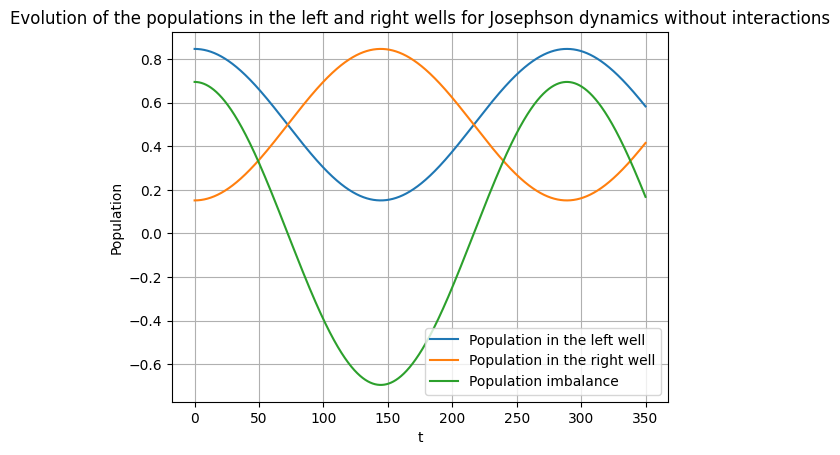

In [49]:
plt.plot(t_j,NL_j,label="Population in the left well")
plt.plot(t_j,NR_j,label="Population in the right well")
plt.plot(t_j,z_j,label="Population imbalance")
plt.grid()
plt.legend()
plt.xlabel("t")
plt.ylabel("Population")
plt.title("Evolution of the populations in the left and right wells for Josephson dynamics without interactions")

Text(0.5, 1.0, 'Evolution of the populations in the left and right wells for Josephson dynamics with weak interactions')

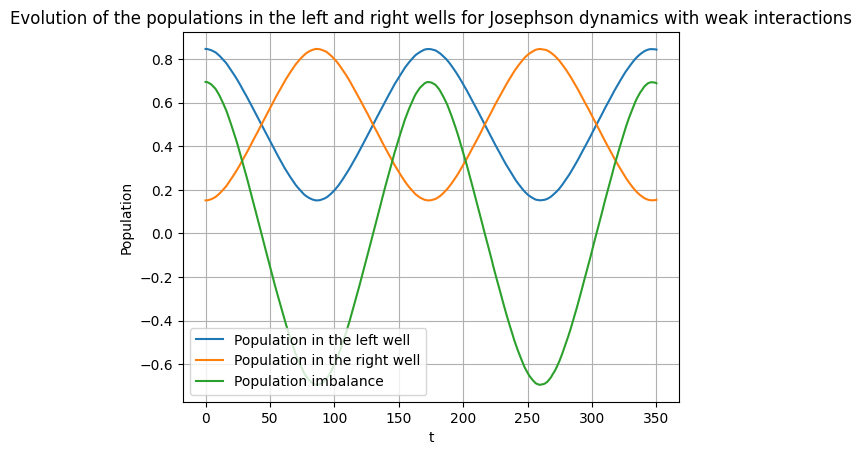

In [50]:
plt.plot(t_j_faible,NL_j_faible,label="Population in the left well")
plt.plot(t_j_faible,NR_j_faible,label="Population in the right well")
plt.plot(t_j_faible,z_j_faible,label="Population imbalance")
plt.grid()
plt.legend()
plt.xlabel("t")
plt.ylabel("Population")
plt.title("Evolution of the populations in the left and right wells for Josephson dynamics with weak interactions")

Text(0.5, 1.0, 'Evolution of the populations in the left and right wells for Josephson dynamics with strong interactions')

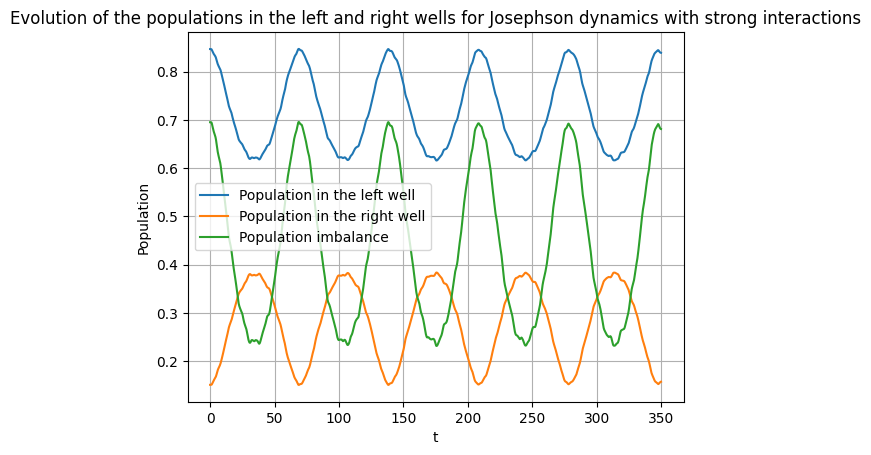

In [51]:
plt.plot(t_j_int,NL_j_int,label="Population in the left well")
plt.plot(t_j_int,NR_j_int,label="Population in the right well")
plt.plot(t_j_int,z_j_int,label="Population imbalance")
plt.grid()
plt.legend()
plt.xlabel("t")
plt.ylabel("Population")
plt.title("Evolution of the populations in the left and right wells for Josephson dynamics with strong interactions")

**Analysis.**
- **Without interactions**, the imbalance $z$ oscillates between $+0.7$ and $-0.7$ with the linear Josephson period $\pi/K \approx 289$: atoms move from one well to the other through tunneling.
- **With weak interactions ($\Lambda = 3$)**, $z$ still changes sign, but the period is shorter (about 173): interactions speed up the oscillation.
- **With strong interactions ($\Lambda = 10$)**, $z$ no longer changes sign and oscillates only between approximately 0.23 and 0.70: most atoms remain in the initial well. This is macroscopic self-trapping.

**Conclusion.** The Gross–Pitaevskii equation in a double well reproduces the two regimes: Josephson oscillations when tunneling dominates, and self-trapping when interactions dominate. This result requires a double well that allows measurable tunneling, and the model remains one-dimensional.

**Animations: Josephson dynamics without and with strong interactions.** See [`josephson_no_interaction.gif`](../figures/josephson_no_interaction.gif) and [`josephson_self_trapping.gif`](../figures/josephson_self_trapping.gif)

## Conclusion

**What was done.** We developed a numerical solver for the one-dimensional Schrödinger equation: diagonalization of the discretized Hamiltonian for stationary states, followed by time integration using explicit Euler and fourth-order Runge–Kutta (RK4) methods. The validated solver was then applied to the scattering of a wave packet by a potential barrier and to the dynamics of a Bose–Einstein condensate in a double well, using the Gross–Pitaevskii equation.

**Main results.**
- **Stationary states.** The spectra and wavefunctions of the infinite square well and of the harmonic oscillator are reproduced. For $n = 100$, the agreement is good for the lowest levels only: the numerical energies lie below the analytical ones, and the discrepancy grows with the level because of the spatial discretization.
- **Time integration.** Explicit Euler is unstable for any time step and cannot be used: a stationary state is visibly distorted after a short time. RK4 preserves stationary states and is stable.
- **Validation of RK4.** The solver reproduces free spreading of a Gaussian packet, reflection from a wall, interference between two packets, and the oscillation of a packet in a harmonic potential with the expected period $\pi$. The mean energy stays constant and the uncertainty relation $\Delta x\,\Delta p \geq 1/2$ is respected.
- **Potential barrier.** For a barrier of height $V_0 = 100$, a packet of comparable energy is reflected with probability 0.66 and transmitted with probability 0.31 ($R + T = 0.97$).
- **Josephson dynamics.** For an initial imbalance $z_0 = 0.7$, the Gross–Pitaevskii equation in a double well reproduces the two regimes expected. Without interactions ($\Lambda = 0$), the population oscillates between the two wells with the linear Josephson period ($\approx 289$). With weak interactions ($\Lambda = 3$), the oscillation is faster (period $\approx 173$) but $z$ still changes sign. With strong interactions ($\Lambda = 10$), $z$ stays between about 0.23 and 0.70: the atoms remain mostly in the initial well, which is macroscopic self-trapping.

**Limitations.**
- The finite-difference scheme is second-order in $\delta x$ and imposes hard walls at $\pm L/2$. Narrow packets are only marginally resolved on the grids used here (for example in the barrier case), which produces small spurious oscillations.
- RK4 is not unitary: the norm drifts slowly.
- The model is one-dimensional. In the Josephson study, self-trapping appears only if the double well allows measurable tunneling and if the interaction energy remains small compared with the gap to the excited states of each well. Only one initial imbalance and three values of $\Lambda$ were studied, so the critical imbalance separating the two regimes has not been located.

**Perspectives.**
- Use a unitary scheme (Crank–Nicolson) or the split-step Fourier method, which are better suited to quantum dynamics.
- Monitor the norm and $\langle x\rangle$ throughout each simulation.
- Study $R$ and $T$ as functions of the incident energy and compare them with the analytical result for a rectangular barrier.
- Scan $z_0$ at fixed $\Lambda$ to locate the critical imbalance, and plot the trajectories in the $(\phi, z)$ plane (relative phase and population imbalance) to compare with the experiment.
